

In [ ]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 6 not upgraded.
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 16 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/root/.local/share/fonts: skipping, no such directory
/root/.fonts: skipping, no such directory
/usr/share/fonts/truetype: skipping, looped directory detected
/usr/share/fonts/truetype/humor-sans: skipping, looped directory detected
/usr/share/fonts/truetype/liberation: skipping, looped directory detected
/usr/share/fonts/truetype/n

In [ ]:
import matplotlib.pyplot as plt

plt.rc('font', family='NanumBarunGothic')

In [ ]:
# '부산교통공사_통합.csv'파일만 올리는 경우

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv('부산교통공사_통합.csv', encoding = 'utf-8')

# 기존 요일 열 제거 후 새로 생성 **요일 - 22년도부터 추가된 열
df = df.drop(columns=['요일'])
df['년월일'] = pd.to_datetime(df['년월일'].astype(object), errors='coerce')
df['요일'] = df['년월일'].dt.day_name()

# 20년도부터 동부산대역 -> "윗반송역" 역명 변경, 역명 통일
df.loc[(df['역명'] == '동부산대역') & (df['년월일'] >= '2020-01-01'), '역명'] = '윗반송역'

# 빠른 구분을 위한 호선 열 추가
df['호선'] = np.select(
    [
        df['역번호'].between(95, 134),
        df['역번호'].between(201, 244),
        df['역번호'].between(301, 317),
        df['역번호'].between(401, 415)
    ],
    [1, 2, 3, 4],
    default=0
)


In [ ]:
# 전체 파일 올리는경우

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob

# CSV 파일 있는 폴더 경로
files = glob.glob("*.csv")

# 모든 csv 읽기 - 인코딩 ** 인코딩가능한 형태 상이하여 여러 타입 작성함
df_list = []
common_encodings = ['utf-8', 'cp949', 'euc-kr', 'latin1']

for file in files:
    check = None
    for enc in common_encodings:
        try:
            # 데이터타입 통일해서 읽음
            check = pd.read_csv(file, dtype=str, encoding=enc)

            # '01시~02시'와 '01시-02시' 형태 통일
            check.columns = check.columns.str.replace('~', '-', regex=False).str.replace(' ', '')

            # 년월일 데이터 타입 datetime으로 변경
            check['년월일'] = pd.to_datetime(check['년월일'], errors='coerce')

            # str/object/datetime 제외 모두 숫자형으로 변환
            numeric_cols = check.columns.difference(['역명', '구분', '년월일'])
            check[numeric_cols] = check[numeric_cols].apply(pd.to_numeric, errors='coerce')

            print(f"{file} 파일 - {enc} 인코딩 형태로 모두 읽음")

            break  # 성공하면 다음 파일로 이동

        except UnicodeDecodeError:
            print(f"***** {file} 파일 {enc} 인코딩 형태로 읽기 실패 *****")
            continue

        except Exception as e:
            print(f"!!!! {file} 파일 {enc} 인코딩 형태로 읽는중 에러 발생: {e} !!!!")
            break # 다른 종류의 오류 발생 시 해당 파일 처리 중단

    if check is not None:
        df_list.append(check)
    else:
        print(f"{file} 파일 인코딩 불가능하여 처리하지 않음")

# 합치기
df = pd.concat(df_list, ignore_index=True)

# 기존 요일 열 제거 후 새로 생성 **요일 - 22년도부터 추가된 열
df = df.drop(columns=['요일'])
df['년월일'] = pd.to_datetime(df['년월일'].astype(object), errors='coerce')
df['요일'] = df['년월일'].dt.day_name()
df['요일번호'] = df['년월일'].dt.weekday

# 20년도부터 동부산대역 -> "윗반송역" 역명 변경, 역명 통일
df.loc[(df['역명'] == '동부산대역') & (df['년월일'] >= '2020-01-01'), '역명'] = '윗반송역'

# 빠른 구분을 위한 호선 열 추가
df['호선'] = np.select(
    [
        df['역번호'].between(95, 134),
        df['역번호'].between(201, 244),
        df['역번호'].between(301, 317),
        df['역번호'].between(401, 415)
    ],
    [1, 2, 3, 4],
    default=0
)


# 저장
df.to_csv("부산교통공사_통합.csv", index=False, encoding='utf-8-sig')

print("완료!")

***** 일별역별시간대별승하차(2022년 12월).csv 파일 utf-8 인코딩 형태로 읽기 실패 *****
일별역별시간대별승하차(2022년 12월).csv 파일 - cp949 인코딩 형태로 모두 읽음
***** 일별 역별 시간대별 승하차(2023년 12월).csv 파일 utf-8 인코딩 형태로 읽기 실패 *****
일별 역별 시간대별 승하차(2023년 12월).csv 파일 - cp949 인코딩 형태로 모두 읽음
***** 일별 역별 시간대별 승하차인원(2024년 12월).csv 파일 utf-8 인코딩 형태로 읽기 실패 *****
일별 역별 시간대별 승하차인원(2024년 12월).csv 파일 - cp949 인코딩 형태로 모두 읽음
일별 역별 시간대별 승하차(2025년 12월).csv 파일 - utf-8 인코딩 형태로 모두 읽음
***** 부산교통공사 시간대별 승하차인원(2020년).csv 파일 utf-8 인코딩 형태로 읽기 실패 *****
부산교통공사 시간대별 승하차인원(2020년).csv 파일 - cp949 인코딩 형태로 모두 읽음
***** 부산교통공사 시간대별 승하차인원(2016년).csv 파일 utf-8 인코딩 형태로 읽기 실패 *****
부산교통공사 시간대별 승하차인원(2016년).csv 파일 - cp949 인코딩 형태로 모두 읽음
***** 부산교통공사 시간대별 승하차인원(2019년).csv 파일 utf-8 인코딩 형태로 읽기 실패 *****
부산교통공사 시간대별 승하차인원(2019년).csv 파일 - cp949 인코딩 형태로 모두 읽음
***** 부산교통공사 시간대별 승하차인원(2017년).csv 파일 utf-8 인코딩 형태로 읽기 실패 *****
부산교통공사 시간대별 승하차인원(2017년).csv 파일 - cp949 인코딩 형태로 모두 읽음
***** 부산교통공사 시간대별 승하차인원(2021년).csv 파일 utf-8 인코딩 형태로 읽기 실패 *****
부산교통공사 시간대별 승하차인원(2021년).csv 파일 - cp949 인코딩 형태로 모두 

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 812602 entries, 0 to 812601
Data columns (total 32 columns):
 #   Column   Non-Null Count   Dtype         
---  ------   --------------   -----         
 0   역번호      812602 non-null  int64         
 1   역명       812602 non-null  object        
 2   년월일      812600 non-null  datetime64[ns]
 3   구분       812600 non-null  object        
 4   합계       812600 non-null  float64       
 5   01시-02시  812600 non-null  float64       
 6   02시-03시  812600 non-null  float64       
 7   03시-04시  812600 non-null  float64       
 8   04시-05시  812600 non-null  float64       
 9   05시-06시  812600 non-null  float64       
 10  06시-07시  812600 non-null  float64       
 11  07시-08시  812600 non-null  float64       
 12  08시-09시  812600 non-null  float64       
 13  09시-10시  812600 non-null  float64       
 14  10시-11시  812600 non-null  float64       
 15  11시-12시  812600 non-null  float64       
 16  12시-13시  812600 non-null  float64       
 17  13시-14시  8

In [ ]:
# 컬럼별 결측치 개수
print(df.isnull().sum())

역번호        0
역명         0
년월일        2
구분         2
합계         2
01시-02시    2
02시-03시    2
03시-04시    2
04시-05시    2
05시-06시    2
06시-07시    2
07시-08시    2
08시-09시    2
09시-10시    2
10시-11시    2
11시-12시    2
12시-13시    2
13시-14시    2
14시-15시    2
15시-16시    2
16시-17시    2
17시-18시    2
18시-19시    2
19시-20시    2
20시-21시    2
21시-22시    2
22시-23시    2
23시-24시    2
24시-01시    2
요일         2
요일번호       2
호선         0
dtype: int64


In [ ]:
# 결측치 있는 행 보기
print(df[df.isnull().any(axis=1)])

        역번호   역명 년월일   구분  합계  01시-02시  02시-03시  03시-04시  04시-05시  05시-06시  \
465614  301  좌수영 NaT  NaN NaN      NaN      NaN      NaN      NaN      NaN   
627890  301  좌수영 NaT  NaN NaN      NaN      NaN      NaN      NaN      NaN   

        ...  18시-19시  19시-20시  20시-21시  21시-22시  22시-23시  23시-24시  24시-01시  \
465614  ...      NaN      NaN      NaN      NaN      NaN      NaN      NaN   
627890  ...      NaN      NaN      NaN      NaN      NaN      NaN      NaN   

         요일  요일번호  호선  
465614  NaN   NaN   3  
627890  NaN   NaN   3  

[2 rows x 32 columns]


In [ ]:
# 결측치 행 제거
df = df.dropna()

In [ ]:
# 재확인
print(df.isnull().sum())

역번호        0
역명         0
년월일        0
구분         0
합계         0
01시-02시    0
02시-03시    0
03시-04시    0
04시-05시    0
05시-06시    0
06시-07시    0
07시-08시    0
08시-09시    0
09시-10시    0
10시-11시    0
11시-12시    0
12시-13시    0
13시-14시    0
14시-15시    0
15시-16시    0
16시-17시    0
17시-18시    0
18시-19시    0
19시-20시    0
20시-21시    0
21시-22시    0
22시-23시    0
23시-24시    0
24시-01시    0
요일         0
요일번호       0
호선         0
dtype: int64


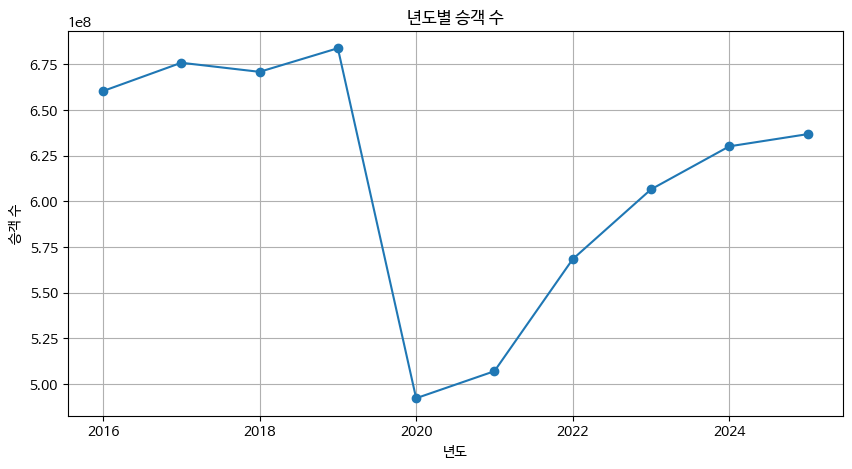

In [ ]:
# 연도별 합계 계산
year_sum = df.groupby(df['년월일'].dt.year)['합계'].sum()

# 그래프
plt.figure(figsize=(10,5))
plt.plot(year_sum.index, year_sum.values, marker='o')

plt.xlabel('년도')
plt.ylabel('승객 수')
plt.title('년도별 승객 수')

plt.grid(True)
plt.show()

-> 코로나가 있었던 해에 수치가 크게 감소하고 이후로 조금씩 증가하는 것을 확인할 수 있음.

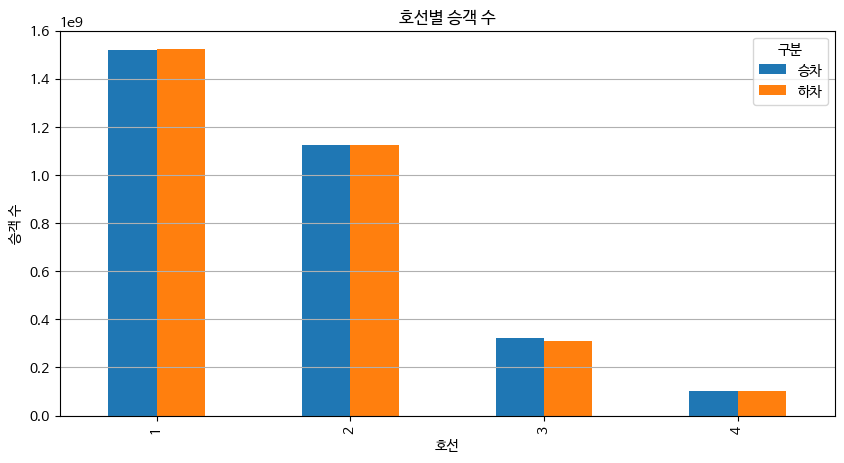

In [ ]:
# 호선별 승하차 합계
line_status = df.groupby(['호선', '구분'])['합계'].sum().unstack()

# 그래프
line_status.plot(kind='bar', figsize=(10,5))

plt.xlabel('호선')
plt.ylabel('승객 수')
plt.title('호선별 승객 수')

plt.grid(axis='y')
plt.show()

-> 1호선 승객 수가 압도적으로 많은 것을 확인 할 수 있다.

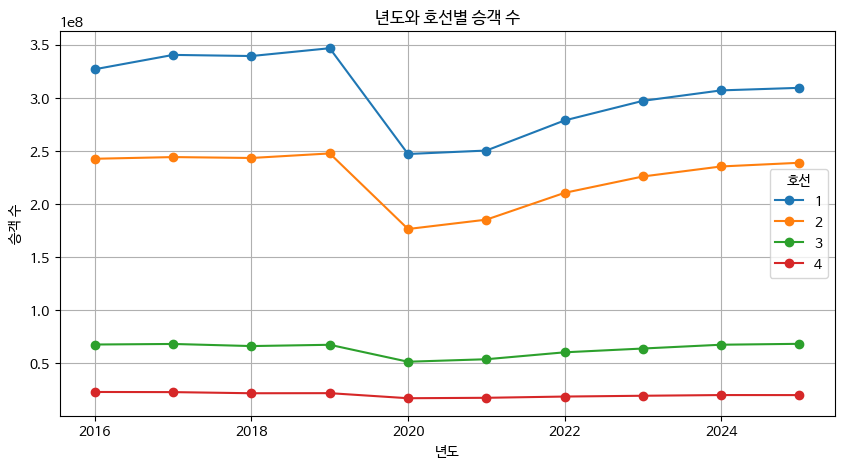

In [ ]:
import matplotlib.pyplot as plt

# 연도별 호선별 합계
year_line = df.groupby([df['년월일'].dt.year, '호선'])['합계'].sum().unstack()

# 그래프
year_line.plot(figsize=(10,5), marker='o')

plt.xlabel('년도')
plt.ylabel('승객 수')
plt.title('년도와 호선별 승객 수')

plt.grid(True)
plt.show()

-> 3호선과 4호선은 코로나의 영향이 1, 2호선에 비해 크지않았던 것을 확인 할 수 있다.

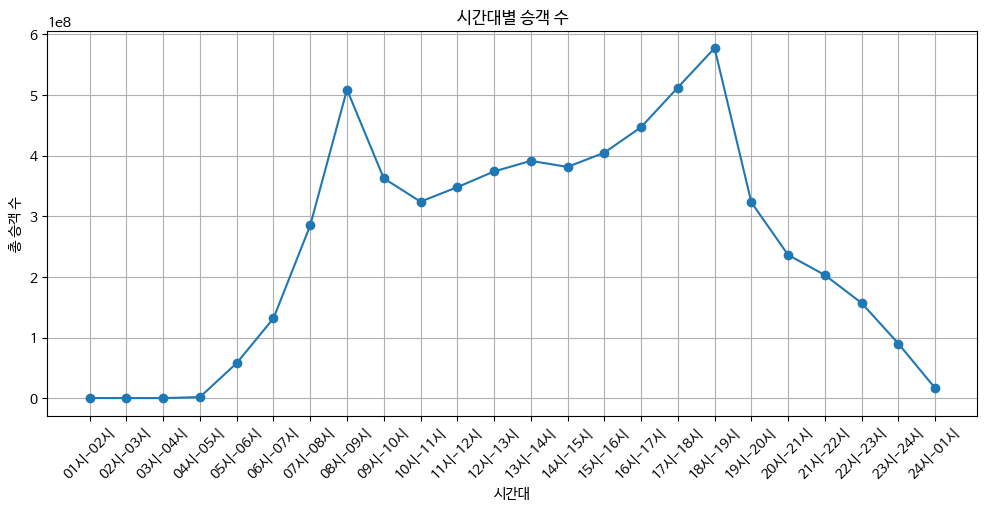

In [ ]:
import matplotlib.pyplot as plt

# 시간대 컬럼만 선택
time_cols = [
    '01시-02시','02시-03시','03시-04시','04시-05시','05시-06시',
    '06시-07시','07시-08시','08시-09시','09시-10시','10시-11시',
    '11시-12시','12시-13시','13시-14시','14시-15시','15시-16시',
    '16시-17시','17시-18시','18시-19시','19시-20시','20시-21시',
    '21시-22시','22시-23시','23시-24시','24시-01시'
]

# 시간대별 합계
time_sum = df[time_cols].sum()

# 그래프
plt.figure(figsize=(12,5))
plt.plot(time_sum.index, time_sum.values, marker='o')

plt.xlabel('시간대')
plt.ylabel('총 승객 수')
plt.title('시간대별 승객 수')

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

-> 출퇴근시간인 08-09시, 18시-19시에 가장 승객이 많은 것을 알 수 있다.

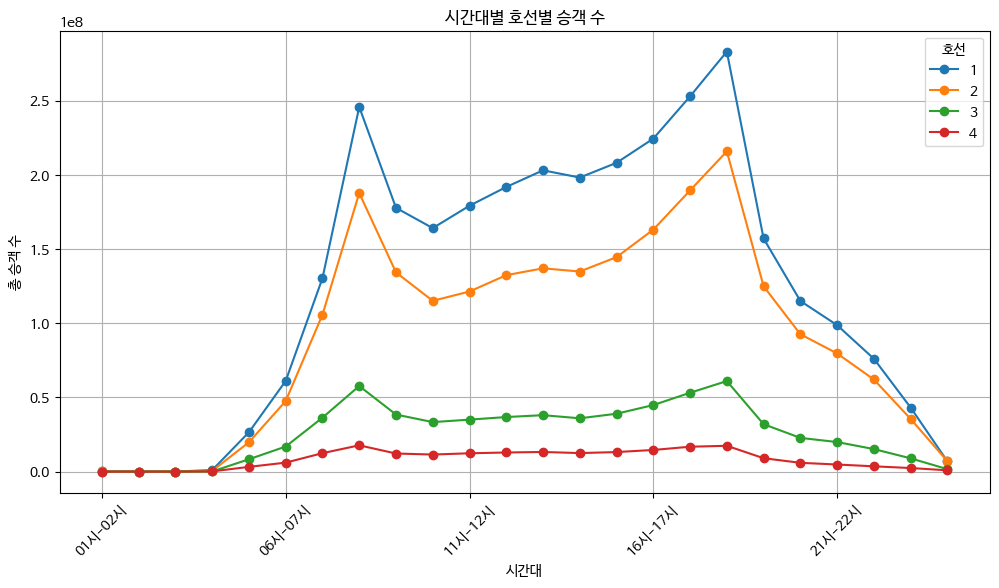

In [ ]:
import matplotlib.pyplot as plt


# 시간대 컬럼
time_cols = [
    '01시-02시','02시-03시','03시-04시','04시-05시','05시-06시',
    '06시-07시','07시-08시','08시-09시','09시-10시','10시-11시',
    '11시-12시','12시-13시','13시-14시','14시-15시','15시-16시',
    '16시-17시','17시-18시','18시-19시','19시-20시','20시-21시',
    '21시-22시','22시-23시','23시-24시','24시-01시'
]

# 호선별 시간대 합계
line_time = df.groupby('호선')[time_cols].sum().T

# 그래프
line_time.plot(figsize=(12,6), marker='o')

plt.xlabel('시간대')
plt.ylabel('총 승객 수')
plt.title('시간대별 호선별 승객 수')

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

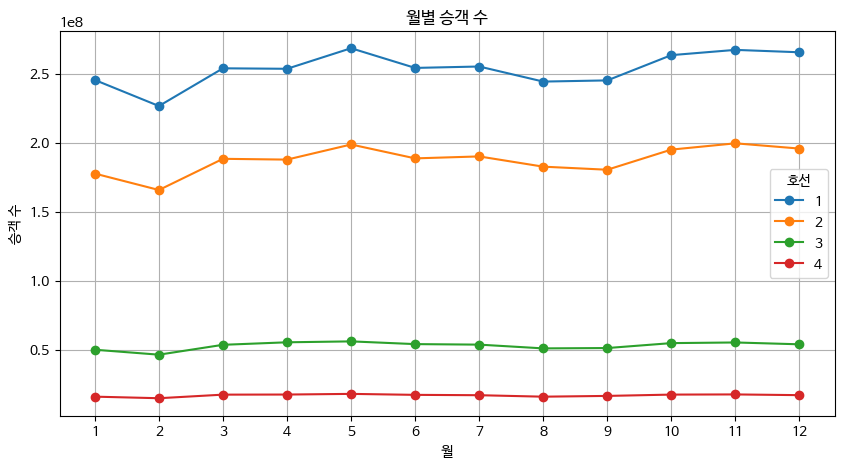

In [ ]:
import matplotlib.pyplot as plt


# 월별 호선별 합계
month_line = df.groupby([df['년월일'].dt.month, '호선'])['합계'].sum().unstack()

# 그래프
month_line.plot(figsize=(10,5), marker='o')

plt.xlabel('월')
plt.ylabel('승객 수')
plt.title('월별 승객 수')

plt.xticks(range(1,13))
plt.grid(True)

plt.show()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) NanumBarunGothic.
  fig.canvas.print_figure(bytes_io, **kw)


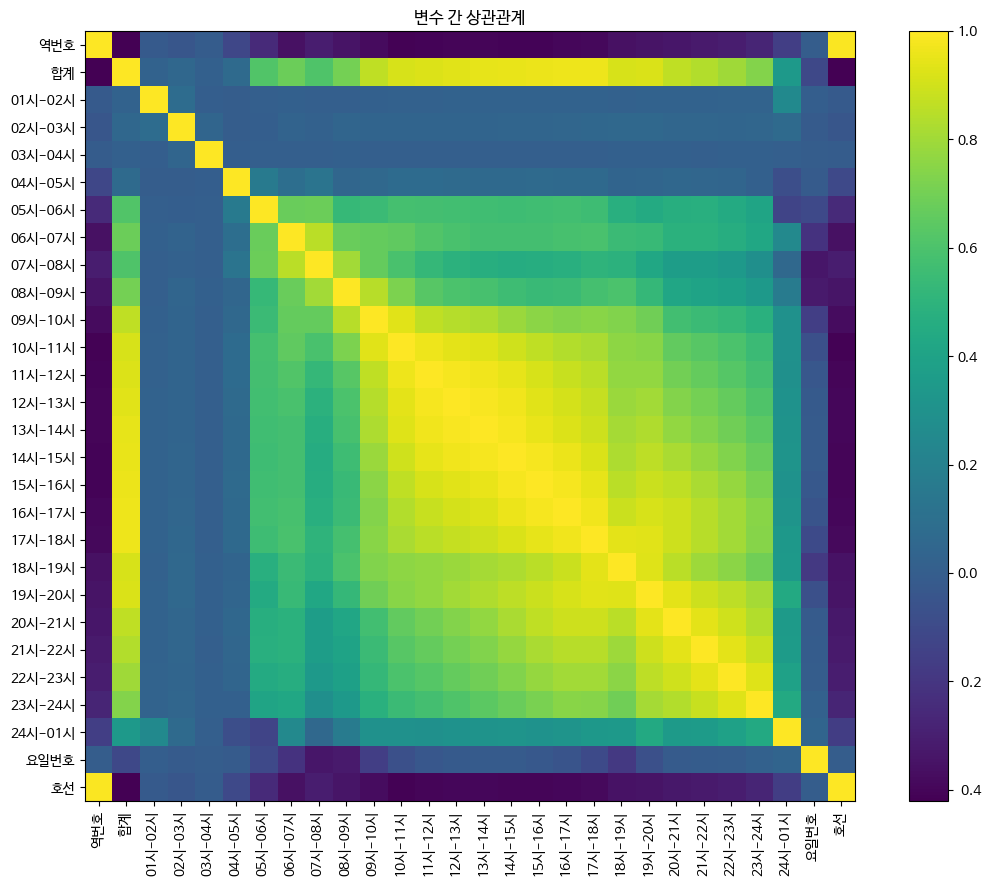

In [ ]:
# 숫자형 컬럼만 선택
numeric_cols = df.select_dtypes(include=['float64', 'int64'])

# 상관계수 계산
corr = numeric_cols.corr()

# heatmap
plt.figure(figsize=(14,10))
plt.imshow(corr, interpolation='nearest')

plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title('변수 간 상관관계')

plt.show()

In [ ]:
result = []

for line in sorted(df['호선'].unique()):
    temp = df[df['호선'] == line]
    corr = temp[time_cols + ['합계']].corr()['합계'].drop('합계').sort_values(ascending=False).head(3)

    for t, v in corr.items():
        result.append([line, t, v])

top3_df = pd.DataFrame(result, columns=['호선', '시간대', '상관계수'])

print(top3_df)

    호선      시간대      상관계수
0    1  17시-18시  0.961395
1    1  16시-17시  0.958822
2    1  15시-16시  0.952215
3    2  17시-18시  0.960988
4    2  15시-16시  0.958663
5    2  16시-17시  0.956324
6    3  14시-15시  0.899991
7    3  13시-14시  0.895343
8    3  11시-12시  0.890643
9    4  13시-14시  0.914602
10   4  14시-15시  0.906859
11   4  12시-13시  0.905312


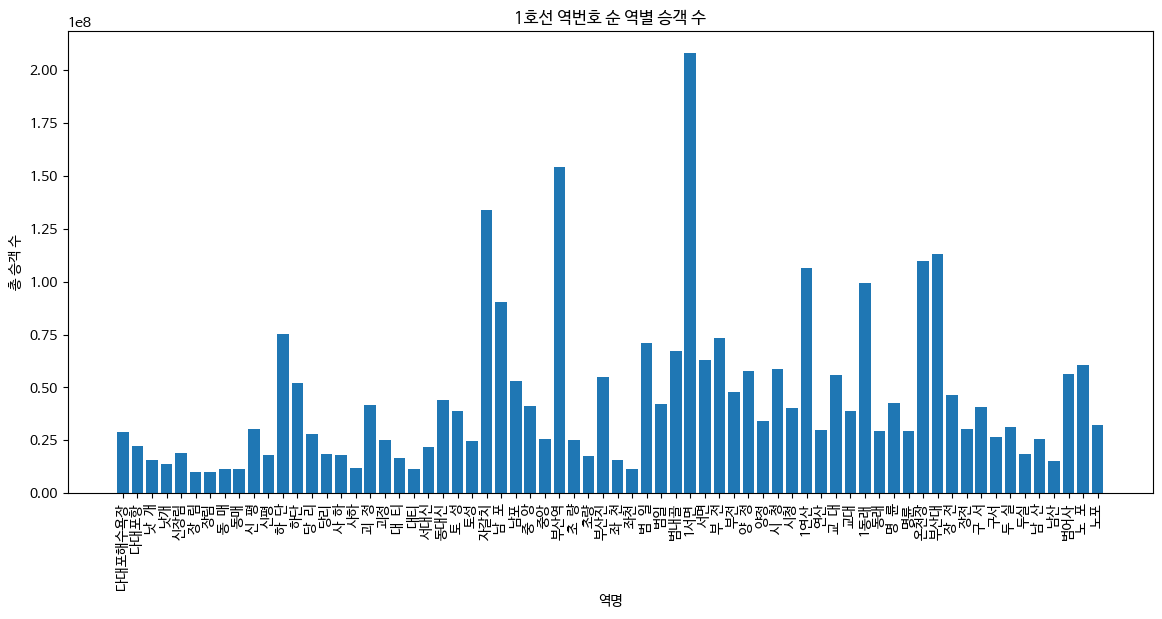

In [ ]:
import matplotlib.pyplot as plt\

# 1호선만 필터링
line1 = df[df['호선'] == 1]

# 역번호+역명 기준 합계
station_sum = line1.groupby(['역번호', '역명'])['합계'].sum().reset_index()

# 역번호 순 정렬
station_sum = station_sum.sort_values('역번호')

# 그래프
plt.figure(figsize=(14,6))
plt.bar(station_sum['역명'], station_sum['합계'])

plt.xlabel('역명')
plt.ylabel('총 승객 수')
plt.title('1호선 역번호 순 역별 승객 수')

plt.xticks(rotation=90)

plt.show()

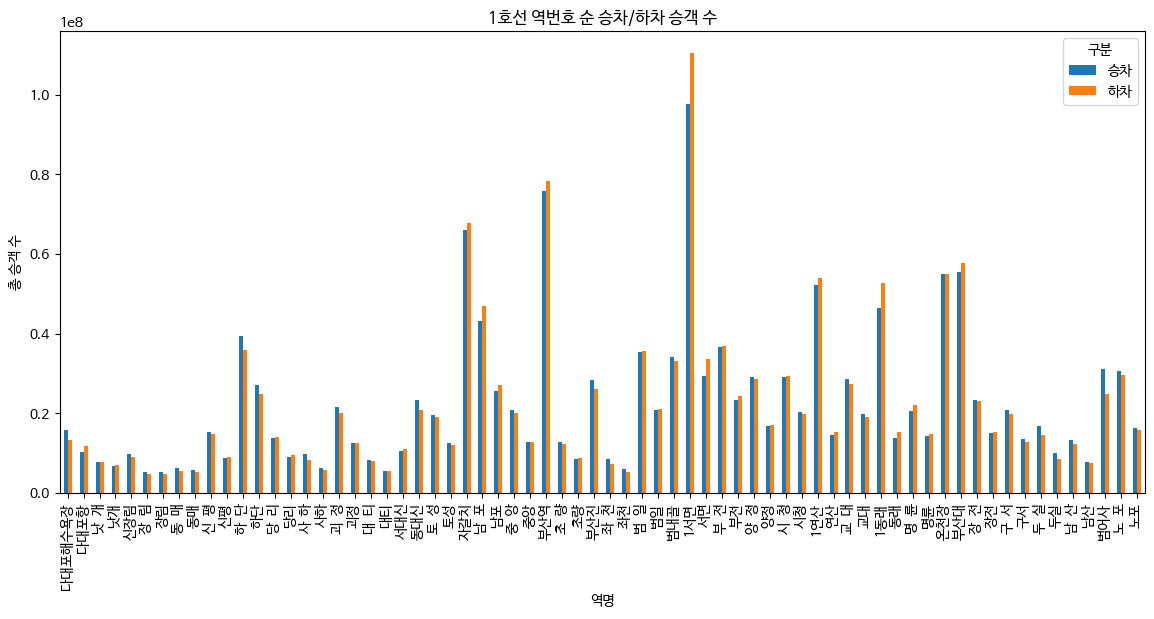

In [ ]:
# 1호선만 필터링
line1 = df[df['호선'] == 1]

# 역번호, 역명, 구분별 합계
station_inout = line1.groupby(['역번호', '역명', '구분'])['합계'].sum().reset_index()

# pivot
pivot = station_inout.pivot(index=['역번호','역명'], columns='구분', values='합계').reset_index()

# 역번호 정렬
pivot = pivot.sort_values('역번호')

# 승차/하차만 그래프
pivot[['승차','하차']].plot(kind='bar', figsize=(14,6))

# x축 역명 설정
plt.xticks(range(len(pivot)), pivot['역명'], rotation=90)

plt.xlabel('역명')
plt.ylabel('총 승객 수')
plt.title('1호선 역번호 순 승차/하차 승객 수')

plt.show()

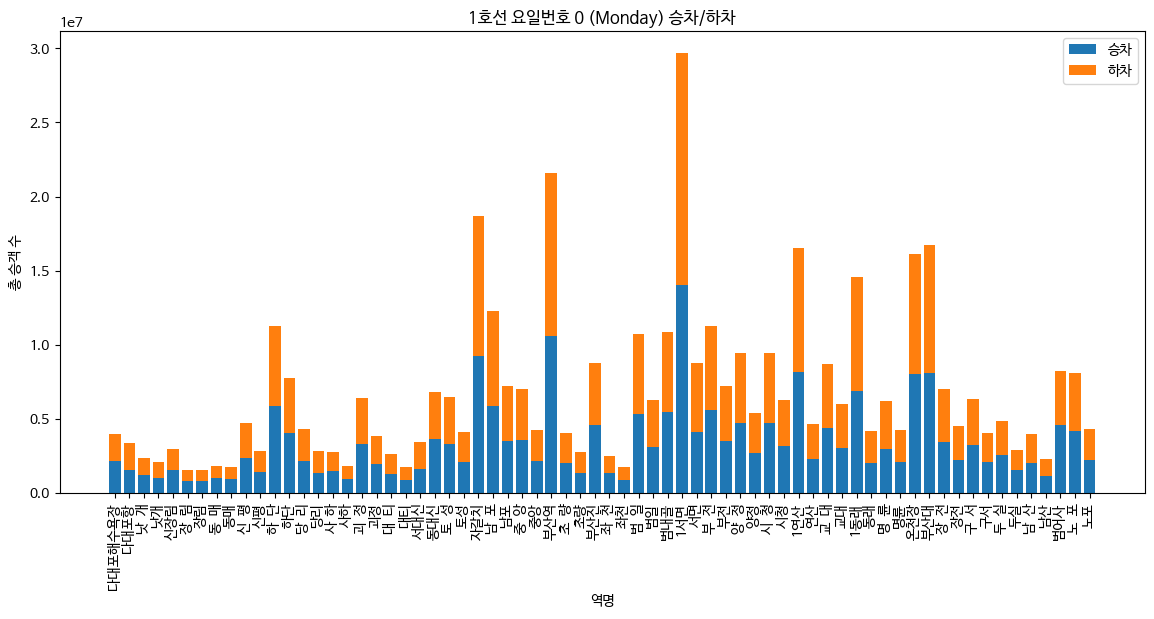

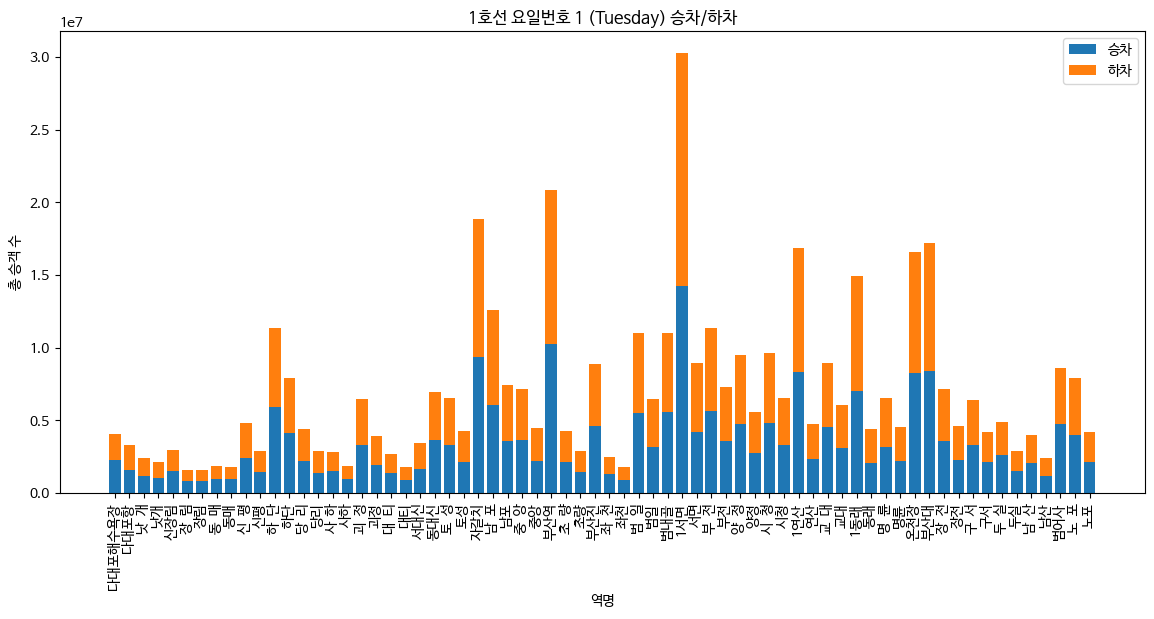

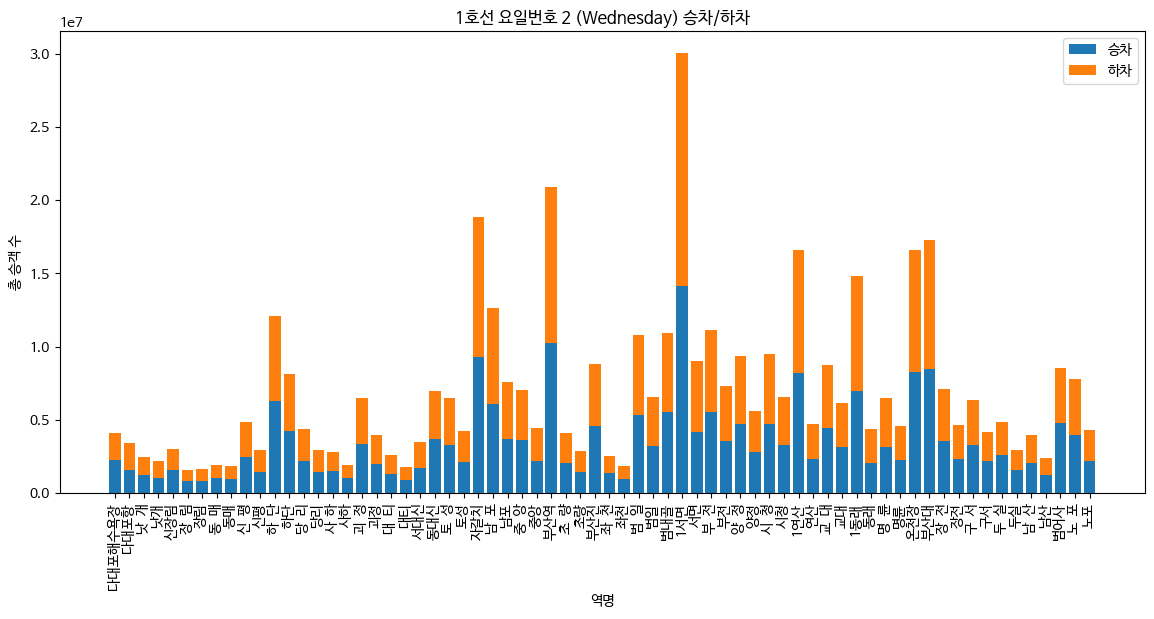

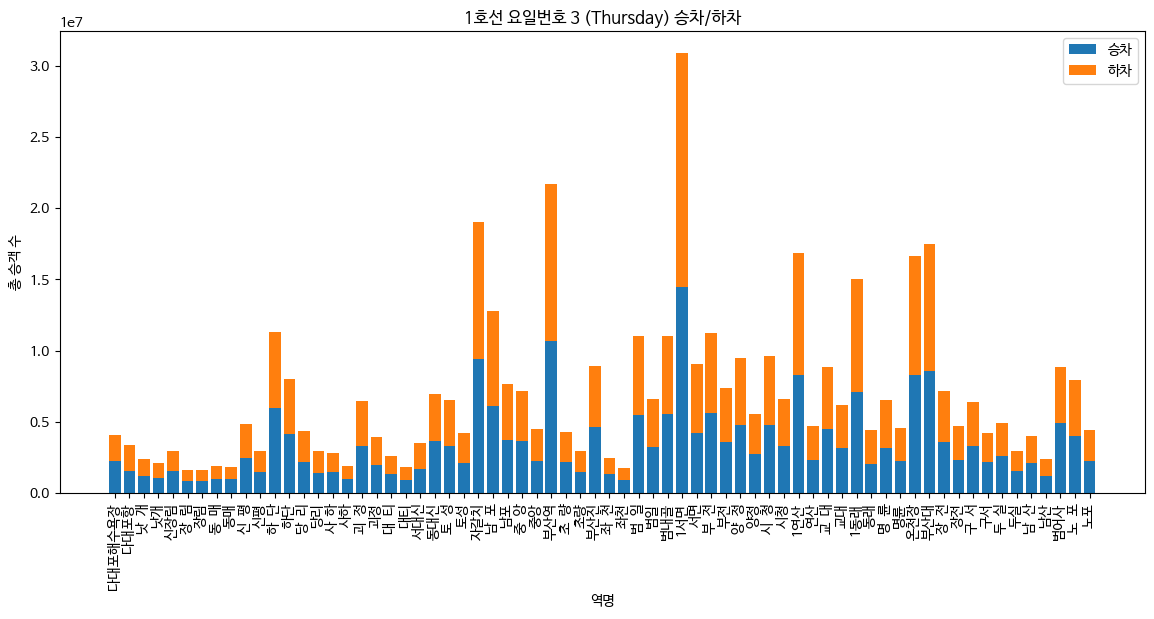

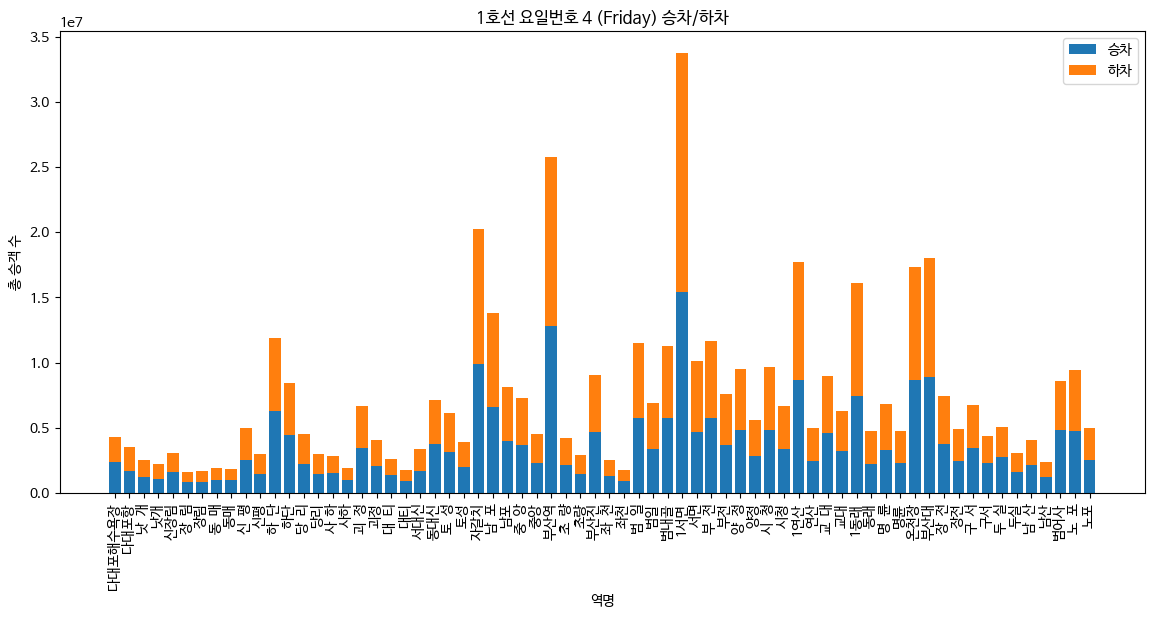

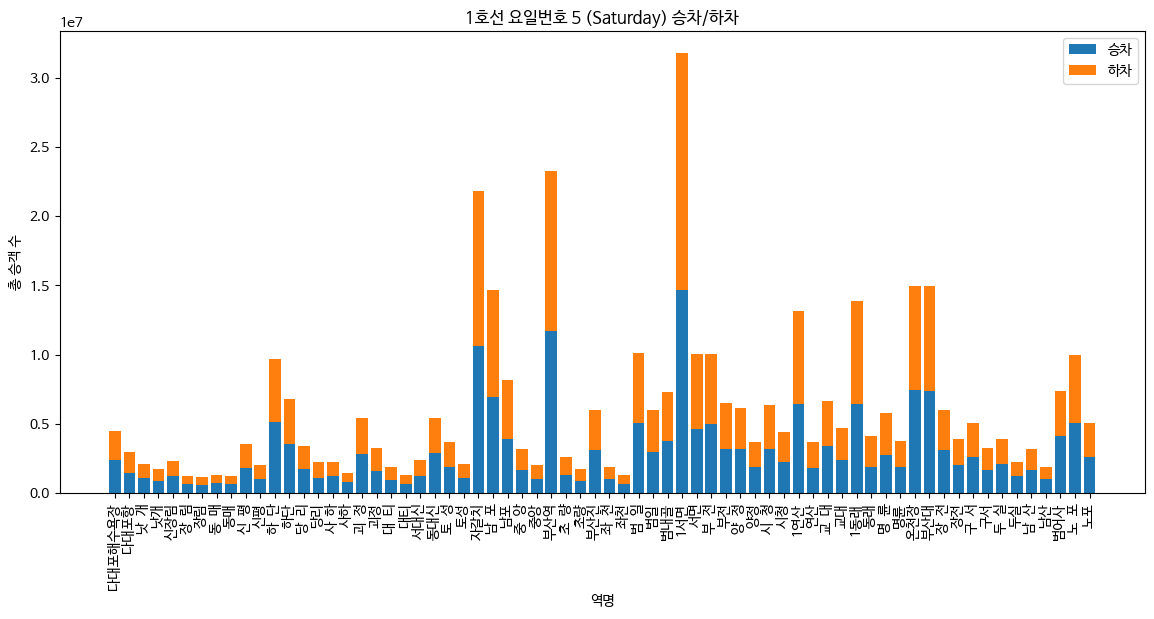

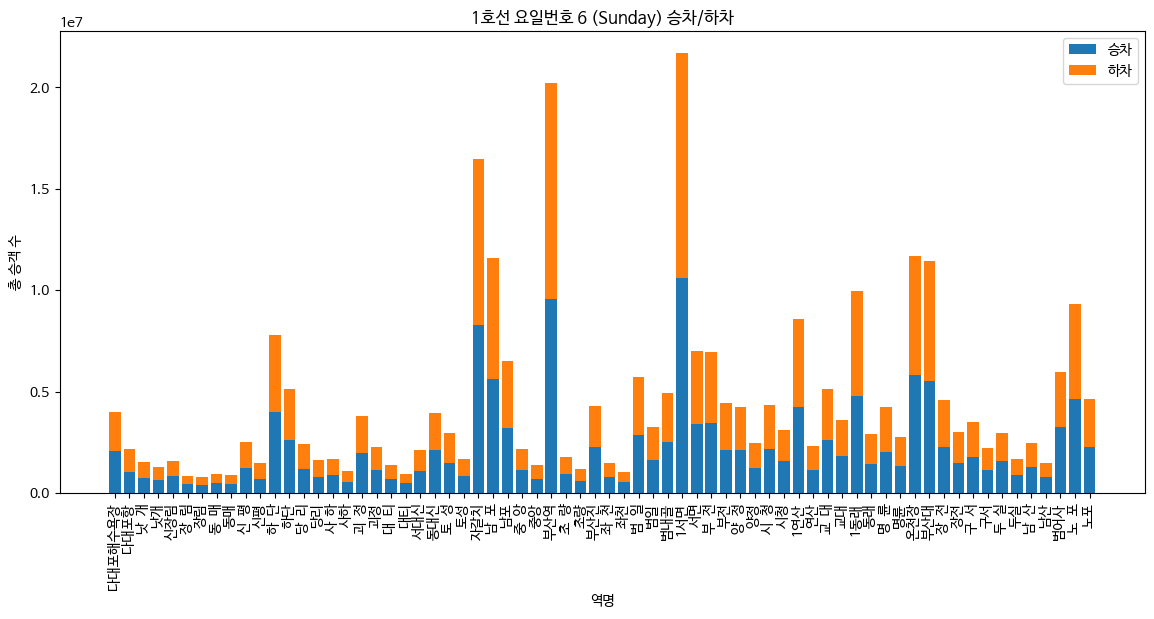

In [ ]:
# 요일명 매핑
weekday_map = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

# 요일번호 반복
for day_num in range(7):
    temp = line1[line1['요일번호'] == day_num]

    station = temp.groupby(['역번호', '역명', '구분'])['합계'].sum().reset_index()

    pivot = station.pivot_table(
        index=['역번호','역명'],
        columns='구분',
        values='합계',
        fill_value=0
    ).reset_index()

    pivot = pivot.sort_values('역번호')

    if '승차' not in pivot.columns:
        pivot['승차'] = 0
    if '하차' not in pivot.columns:
        pivot['하차'] = 0

    # 그래프
    plt.figure(figsize=(14,6))
    plt.bar(pivot['역명'], pivot['승차'], label='승차')
    plt.bar(pivot['역명'], pivot['하차'], bottom=pivot['승차'], label='하차')

    plt.xticks(rotation=90)
    plt.title(f'1호선 요일번호 {day_num} ({weekday_map[day_num]}) 승차/하차')
    plt.xlabel('역명')
    plt.ylabel('총 승객 수')

    plt.legend()
    plt.show()

In [ ]:
# 환승역 리스트
transfer_stations = [
    '서면', '연산', '덕천', '동래', '미남', '수영', '대저', '사상'
]

# 환승역 데이터만 추출
transfer = df[df['역명'].isin(transfer_stations)]

# 역별 승하차 합계
station = transfer.groupby(['역명', '구분'])['합계'].sum().reset_index()

pivot = station.pivot_table(
    index='역명',
    columns='구분',
    values='합계',
    fill_value=0
).reset_index()

# 없을 경우 대비
if '승차' not in pivot.columns:
    pivot['승차'] = 0
if '하차' not in pivot.columns:
    pivot['하차'] = 0

# 총합 기준 정렬
pivot['총합'] = pivot['승차'] + pivot['하차']
pivot = pivot.sort_values('총합', ascending=False)

print(pivot)

구분  역명          승차          하차           총합
5   서면  49997335.0  54563593.0  104560928.0
4   사상  30745630.0  31113632.0   61859262.0
7   연산  22809287.0  22684867.0   45494154.0
6   수영  21491140.0  20815877.0   42307017.0
2   동래  15647413.0  17463437.0   33110850.0
1   덕천  14256857.0  15339347.0   29596204.0
3   미남  14111760.0  13230054.0   27341814.0
0   대저  11551838.0  10141512.0   21693350.0


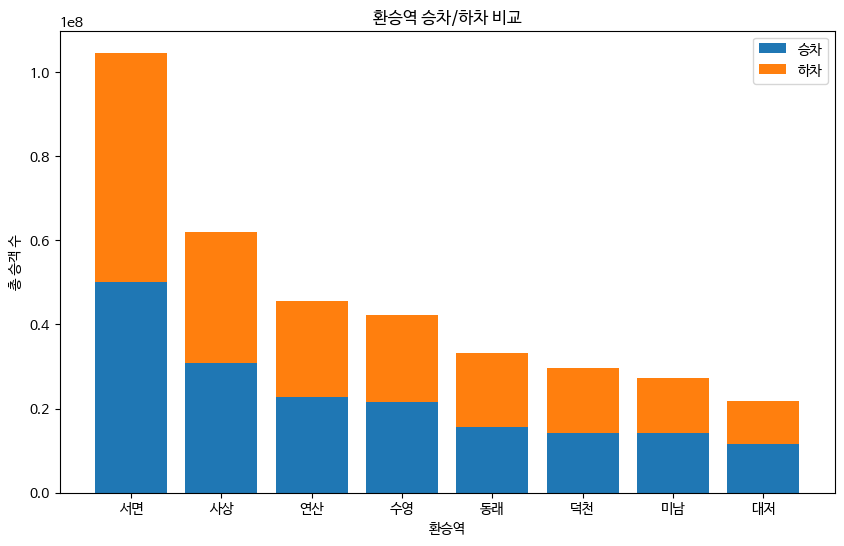

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.bar(pivot['역명'], pivot['승차'], label='승차')
plt.bar(pivot['역명'], pivot['하차'], bottom=pivot['승차'], label='하차')

plt.title('환승역 승차/하차 비교')
plt.xlabel('환승역')
plt.ylabel('총 승객 수')

plt.legend()
plt.show()